# Evaluering av RAG-chattbot
## Kostråd för gravida, spädbarn och småbarn

Denna notebook utvärderar chattboten genom att:
1. Kontrollera chunkningen och kalibrera gränsen för "vet inte"
2. Köra testfrågor genom **exakt samma kod som appen** (`rag.py`)
3. Låta Gemini bedöma svaren på en skala 1–5 (LLM-as-a-judge)
4. Sammanfatta resultaten i en tabell och ett diagram

Testfrågorna är av fem typer:
- **fakta** – svaret finns i källorna
- **kombinera** – svaret kräver att flera textstycken kombineras
- **delvis** – bara en del av frågan finns i källorna, resten ska botten säga att den inte vet
- **vet_inte** – svaret finns INTE i källorna, botten ska säga att den inte vet
- **ålder** – frågan saknar barnets ålder, botten ska fråga efter den

**Betygsskala:** 5 = utmärkt · 4 = bra · 3 = godkänt · 2 = bristfälligt · 1 = underkänt

In [3]:
import time
import pandas as pd
import matplotlib.pyplot as plt

# Importera samma kunskapsbas som Streamlit-appen och api.py använder.
# Ändras något i rag.py testas ändringen automatiskt här också.
import rag
from rag import Kunskapsbas

kb = Kunskapsbas()
print(f"✅ {len(kb.chunks)} chunkar från {len(rag.KÄLLOR)} PDF-filer")

✅ 156 chunkar från 11 PDF-filer


## Steg 1 – Kontrollera chunkningen
Förra versionen gav **1 chunk** eftersom pypdf inte ger tomma rader mellan stycken. Här syns hur texten fördelas nu.

In [4]:
# En rad per chunk: källa, sida och längd
chunk_df = pd.DataFrame([{"källa": c["källa"], "sida": c["sida"], "tecken": len(c["text"])} for c in kb.chunks])

# Antal chunkar per källa
print(chunk_df["källa"].value_counts().to_string())
# Kortaste, genomsnittliga och längsta chunken
print(f"\nTecken per chunk – min: {chunk_df.tecken.min()}, snitt: {chunk_df.tecken.mean():.0f}, max: {chunk_df.tecken.max()}")

källa
Livsmedelsverket – Bra mat för spädbarn under ett år (broschyr)    44
Livsmedelsverket – Bra mat när du är gravid (lättläst)             22
Livsmedelsverket – Kostråd för spädbarn                            17
Livsmedelsverket – Vegansk mat till barn                           13
1177 – Barnets mat och dryck upp till ett år                       12
Livsmedelsverket – Kostråd för barn 1–2 år                         12
Livsmedelsverket – Mat att undvika när du är gravid                12
Livsmedelsverket – Vegetarisk mat till barn                         8
Livsmedelsverket – Näring för gravida                               7
Livsmedelsverket – Vegokunskap för gravida och ammande              6
Livsmedelsverket – Hur mycket mat är lagom när du är gravid?        3

Tecken per chunk – min: 87, snitt: 735, max: 1000


## Steg 2 – Kalibrera gränsen för "vet inte" (`MIN_LIKHET`)
Om den bästa träffen har lägre likhet än `rag.MIN_LIKHET` svarar botten att den inte vet.
Jämför siffrorna nedan: frågor inom ämnet ska ligga **över** gränsen, frågor utanför ämnet **under**.
Justera `MIN_LIKHET` i `rag.py` om de överlappar.

In [5]:
kalibrering = [
    ("inom ämnet", "Kan jag ge honung till min bebis?"),
    ("inom ämnet", "Hur mycket kaffe får jag dricka som gravid?"),
    ("inom ämnet", "När kan barnet börja äta vanlig mat?"),
    ("inom ämnet", "Behöver ett barn som äter veganskt tillskott?"),
    ("utanför ämnet", "Vad kostar en barnvagn?"),
    ("utanför ämnet", "Hur många timmar ska en tvååring sova?"),
    ("utanför ämnet", "Vilket fotbollslag vann allsvenskan förra året?"),
]

rader = []
for typ, fråga in kalibrering:
    bästa = kb.hämta([fråga])[0]   # bara den bästa träffen
    rader.append({"typ": typ, "fråga": fråga, "högsta likhet": round(bästa["likhet"], 3), "källa": bästa["källa"]})
    time.sleep(1)  # undvik rate limiting

print(f"Nuvarande gräns MIN_LIKHET = {rag.MIN_LIKHET}\n")
print(pd.DataFrame(rader).to_string(index=False))

Nuvarande gräns MIN_LIKHET = 0.5

          typ                                           fråga  högsta likhet                                                           källa
   inom ämnet               Kan jag ge honung till min bebis?          0.757 Livsmedelsverket – Bra mat för spädbarn under ett år (broschyr)
   inom ämnet     Hur mycket kaffe får jag dricka som gravid?          0.786             Livsmedelsverket – Mat att undvika när du är gravid
   inom ämnet            När kan barnet börja äta vanlig mat?          0.781                         Livsmedelsverket – Kostråd för spädbarn
   inom ämnet   Behöver ett barn som äter veganskt tillskott?          0.795                        Livsmedelsverket – Vegansk mat till barn
utanför ämnet                         Vad kostar en barnvagn?          0.601                    1177 – Barnets mat och dryck upp till ett år
utanför ämnet          Hur många timmar ska en tvååring sova?          0.662                      Livsmedelsverket – Kos

## Steg 3 – Testfrågor

In [6]:
testfrågor = [
    # --- fakta: svaret finns i källorna ---
    {"typ": "fakta", "fråga": "Kan jag ge honung till min bebis på 8 månader?",
     "förväntat": "Nej, honung ska inte ges till barn under ett år eftersom det kan innehålla bakteriesporer som bildar giftet botulin."},
    {"typ": "fakta", "fråga": "Hur mycket kaffe får jag dricka under graviditeten?",
     "förväntat": "Max 200 mg koffein per dag, ungefär 2 koppar bryggkaffe."},
    {"typ": "fakta", "fråga": "Behöver mitt barn på 6 månader D-droppar?",
     "förväntat": "Ja, barn behöver D-droppar dagligen upp till två års ålder."},
    {"typ": "fakta", "fråga": "Kan mitt barn på 18 månader dricka risdryck?",
     "förväntat": "Nej, risdryck innehåller arsenik och bör inte ges till barn under sex år."},
    {"typ": "fakta", "fråga": "Ska jag ta folsyra när jag är gravid?",
     "förväntat": "Ja, 400 mikrogram folsyra per dag rekommenderas, helst från innan graviditeten till vecka 12."},
    {"typ": "fakta", "fråga": "Får jag äta gravad lax när jag är gravid?",
     "förväntat": "Ja, men köpt gravad och rökt fisk bör ha varit förpackad i högst en vecka (risk för listeria). Egengravad fisk ska göras av färsk fisk och ätas inom en vecka."},
    # --- kombinera: svaret kräver flera textstycken ---
    {"typ": "kombinera", "fråga": "Mitt barn är 10 månader och äter veganskt, vad behöver hon?",
     "förväntat": "Vitamin B12 och D-vitamin som tillskott eller via berikade produkter, järnberikad gröt/välling, och uppmärksamhet på t.ex. järn, kalcium och jod. Inga risdrycker. Svaret ska kombinera råd om vegansk mat med råd för barnets ålder."},
    # --- delvis: bara en del av frågan finns i källorna ---
    {"typ": "delvis", "fråga": "Kan min bebis på 8 månader äta honung, och hur många timmar ska hon sova per natt?",
     "förväntat": "Nej till honung (under ett år). Botten ska säga tydligt att den inte vet hur mycket barnet ska sova, eftersom det inte finns i källorna."},
    # --- vet_inte: svaret finns inte i källorna ---
    {"typ": "vet_inte", "fråga": "Vad kostar en barnvagn?",
     "förväntat": "Botten ska säga att den inte vet, eftersom frågan ligger utanför källmaterialet. Den får inte hitta på ett svar."},
    {"typ": "vet_inte", "fråga": "Vilken vaccination ska mitt barn få vid 12 månader?",
     "förväntat": "Botten ska säga att den inte vet och hänvisa till BVC/1177, eftersom vaccinationer inte finns i källorna."},
    # --- ålder: botten ska fråga efter barnets ålder ---
    {"typ": "ålder", "fråga": "Kan mitt barn äta ägg?",
     "förväntat": "Botten ska fråga hur gammalt barnet är innan den ger ett råd."},
]
print(f"✅ {len(testfrågor)} testfrågor redo")

✅ 11 testfrågor redo


## Steg 4 – Kör testfrågorna genom chattboten

In [7]:
print("Kör testfrågor... (detta kan ta några minuter)\n")

resultat = []
for i, test in enumerate(testfrågor):
    print(f"Fråga {i+1}/{len(testfrågor)}: {test['fråga'][:50]}")
    svar = kb.svara(test["fråga"], historik=[], språk="Svenska")   # samma funktion som appen anropar
    resultat.append({**test, "svar": svar["svar"], "källor": ", ".join(svar["källor"]) or "(inga)"})
    time.sleep(3)  # undvik rate limiting

print("\n✅ Alla svar hämtade!")

Kör testfrågor... (detta kan ta några minuter)

Fråga 1/11: Kan jag ge honung till min bebis på 8 månader?
Fråga 2/11: Hur mycket kaffe får jag dricka under graviditeten
Fråga 3/11: Behöver mitt barn på 6 månader D-droppar?
Fråga 4/11: Kan mitt barn på 18 månader dricka risdryck?
Fråga 5/11: Ska jag ta folsyra när jag är gravid?
Fråga 6/11: Får jag äta gravad lax när jag är gravid?
Fråga 7/11: Mitt barn är 10 månader och äter veganskt, vad beh
Fråga 8/11: Kan min bebis på 8 månader äta honung, och hur mån
Fråga 9/11: Vad kostar en barnvagn?
Fråga 10/11: Vilken vaccination ska mitt barn få vid 12 månader
Fråga 11/11: Kan mitt barn äta ägg?

✅ Alla svar hämtade!


## Steg 5 – Låt Gemini bedöma svaren (LLM-as-a-judge)

In [8]:
def bedöm_svar(fråga, förväntat, svar):
    prompt = f"""
    Du är en expert på barnhälsa och kostråd. Bedöm kvaliteten på ett svar från en chattbot.

    Fråga: {fråga}
    Förväntat svar / förväntat beteende (facit): {förväntat}
    Chattbotens svar: {svar}

    Om facit säger att botten ska säga att den inte vet: ge 5 om den tydligt säger att den inte vet,
    och 1 om den ändå hittar på ett svar.
    Om facit säger att bara en del finns i källorna: dra ner betyget om botten hittar på svar på den del som saknas.

    Bedöm svaret på en skala 1–5:
    5 = Utmärkt – korrekt, fullständigt och tydligt
    4 = Bra – korrekt men kan vara mer fullständigt
    3 = Godkänt – delvis korrekt eller otydligt
    2 = Bristfälligt – felaktigt eller missar viktig information
    1 = Underkänt – fel svar, påhittat svar eller inget svar

    Svara ENDAST i detta format:
    BETYG: [siffra 1-5]
    MOTIVERING: [en mening]
    """
    try:
        text = kb.client.models.generate_content(model=rag.CHATT_MODELL, contents=prompt).text.strip()
        # Plocka ut raderna som börjar med BETYG: och MOTIVERING:
        betyg_rad = [r for r in text.split("\n") if r.startswith("BETYG:")]
        motivering_rad = [r for r in text.split("\n") if r.startswith("MOTIVERING:")]
        betyg = int(betyg_rad[0].replace("BETYG:", "").strip()) if betyg_rad else 0
        motivering = motivering_rad[0].replace("MOTIVERING:", "").strip() if motivering_rad else "Kunde inte bedöma"
        return betyg, motivering
    except Exception as e:
        return 0, f"Fel vid bedömning: {e}"

print("Bedömer svar...\n")
for i, r in enumerate(resultat):
    print(f"Bedömer svar {i+1}/{len(resultat)}...")
    r["betyg"], r["motivering"] = bedöm_svar(r["fråga"], r["förväntat"], r["svar"])
    time.sleep(3)
print("\n✅ Alla svar bedömda!")

Bedömer svar...

Bedömer svar 1/11...
Bedömer svar 2/11...
Bedömer svar 3/11...
Bedömer svar 4/11...
Bedömer svar 5/11...
Bedömer svar 6/11...
Bedömer svar 7/11...
Bedömer svar 8/11...
Bedömer svar 9/11...
Bedömer svar 10/11...
Bedömer svar 11/11...

✅ Alla svar bedömda!


## Steg 6 – Visa resultat

In [9]:
df = pd.DataFrame(resultat)

pd.set_option("display.max_colwidth", 80)
print(df[["typ", "fråga", "betyg", "källor", "motivering"]].to_string(index=False))

# Snittbetyg totalt och per typ av fråga
print(f"\nGenomsnittligt betyg: {df['betyg'].mean():.2f} / 5")
print(df.groupby("typ")["betyg"].mean().round(2).to_string())

      typ                                                                              fråga  betyg                                                                                                                                                    källor                                                                                                                                                                                                 motivering
    fakta                                     Kan jag ge honung till min bebis på 8 månader?      5    Livsmedelsverket – Bra mat för spädbarn under ett år (broschyr), 1177 – Barnets mat och dryck upp till ett år, Livsmedelsverket – Kostråd för spädbarn                                                            Svaret är korrekt, fullständigt och tydligt, förklarar risken med botulin och anger den rekommenderade åldersgränsen samt ger relevanta källor.
    fakta                                Hur mycket kaffe får jag dricka under gravidi

## Steg 7 – Visualisera resultaten

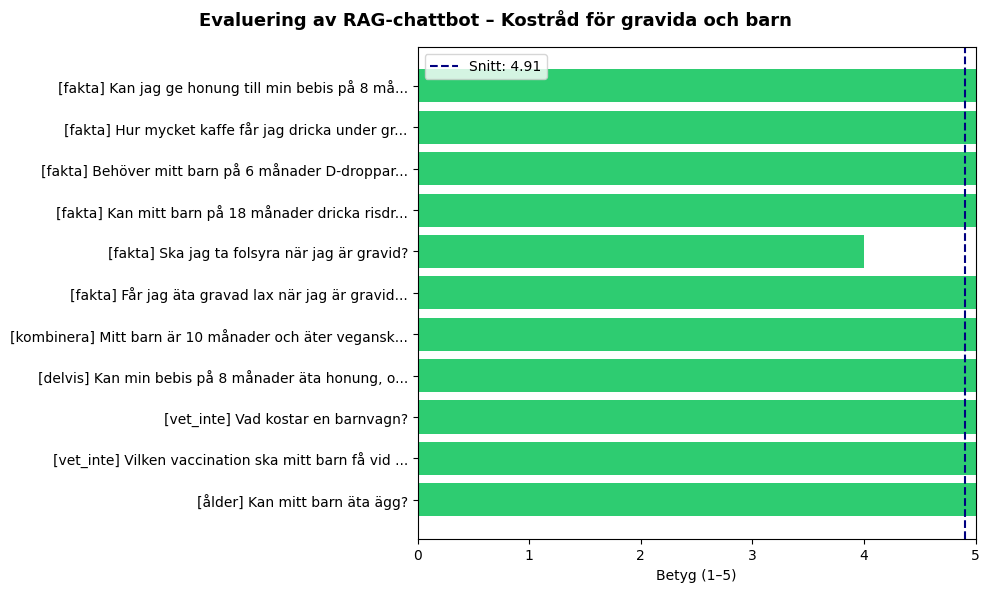

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle("Evaluering av RAG-chattbot – Kostråd för gravida och barn", fontsize=13, fontweight="bold")

# Grön = bra (4–5), orange = godkänt (3), röd = dåligt (1–2)
färger = ["#2ecc71" if b >= 4 else "#f39c12" if b == 3 else "#e74c3c" for b in df["betyg"]]
# Korta ner långa frågor och visa typen framför
etiketter = [f"[{t}] " + (f[:40] + "..." if len(f) > 40 else f) for t, f in zip(df["typ"], df["fråga"])]

ax.barh(etiketter, df["betyg"], color=färger)
ax.set_xlim(0, 5)
ax.set_xlabel("Betyg (1–5)")
ax.axvline(x=df["betyg"].mean(), color="navy", linestyle="--", label=f"Snitt: {df['betyg'].mean():.2f}")
ax.invert_yaxis()   # första frågan överst
ax.legend()

plt.tight_layout()
plt.savefig("evaluering_resultat.png", dpi=150, bbox_inches="tight")
plt.show()

## Steg 8 – Visa detaljerade svar

In [11]:
for i, r in enumerate(resultat):
    print(f"\n{'='*70}\nFRÅGA {i+1} [{r['typ']}] – Betyg: {r['betyg']}/5\n{'='*70}")
    print(f"❓ Fråga:      {r['fråga']}")
    print(f"✅ Förväntat:  {r['förväntat']}")
    print(f"🤖 Chattboten: {r['svar']}")
    print(f"📚 Källor:     {r['källor']}")
    print(f"📝 Motivering: {r['motivering']}")


FRÅGA 1 [fakta] – Betyg: 5/5
❓ Fråga:      Kan jag ge honung till min bebis på 8 månader?
✅ Förväntat:  Nej, honung ska inte ges till barn under ett år eftersom det kan innehålla bakteriesporer som bildar giftet botulin.
🤖 Chattboten: Nej, du bör inte ge honung till din bebis som är 8 månader gammal.

Honung kan innehålla bakteriesporer som i sällsynta fall kan utvecklas till ett farligt gift, botulin, i barnets tarmar. Det är säkrast att vänta tills barnet har fyllt ett år innan du ger honung.

📚 Livsmedelsverket – Bra mat för spädbarn under ett år (broschyr) · 1177 – Barnets mat och dryck upp till ett år · Livsmedelsverket – Kostråd för spädbarn
📚 Källor:     Livsmedelsverket – Bra mat för spädbarn under ett år (broschyr), 1177 – Barnets mat och dryck upp till ett år, Livsmedelsverket – Kostråd för spädbarn
📝 Motivering: Svaret är korrekt, fullständigt och tydligt, förklarar risken med botulin och anger den rekommenderade åldersgränsen samt ger relevanta källor.

FRÅGA 2 [fakta] – B

## Sammanfattning och slutsats

**Resultat:** snittbetyg **4,91 av 5** på 11 testfrågor (10 frågor fick 5, en fick 4).

- **Fakta och kombinera:** svaren var korrekta och bygger på rätt källor. Lägst betyg (4) fick folsyrafrågan, där svaret var korrekt men saknade den uttryckliga dosrekommendationen.
- **Delvis / vet inte:** botten svarade på det som finns i källorna och sa tydligt att den inte vet resten (t.ex. barnvagnspris och vaccinationer) – den hittar inte på.
- **Ålder:** när barnets ålder saknades frågade botten efter den i stället för att gissa.
- **Gränsen `MIN_LIKHET = 0,5`** skiljer frågor inom ämnet (likhet 0,76–0,80) från frågor utanför (0,54–0,66).

**Begränsningar:** bara 11 testfrågor, och domaren är också en AI (Gemini), så resultatet är en indikation och inte en klinisk granskning. Evalueringen kördes med de första 11 källorna – senare tillkom källor om amning, handledningen 0–5 år, översättning av frågor på andra språk och sökning per delfråga, som har testats manuellt i appen.

Obs: den förra evalueringen (5.00/5) gjordes när all text låg i en enda chunk, så Gemini fick alltid se hela källmaterialet. Den här evalueringen testar den riktiga sökningen, och även att botten säger "vet inte" och frågar efter ålder.